# Static analysis and the Drebin feature sets

The project's feature vocabulary comes from the **Drebin** approach: an APK is statically analysed — its manifest and its disassembled code — and the findings are grouped into feature sets **S1–S8** (hardware, permissions, components, intents, restricted/suspicious API calls, used permissions, network addresses, and more). This notebook is the study that grounded that choice: what an APK contains, what each feature set means, and the code that extracts them.

The original's own explanatory markdown is kept throughout — it is the clearest introduction in the repository to what the features actually are.

*Consolidated from `Static_Analysis.ipynb` (originally in `a_malware`). A short VirusTotal snippet at the end of the original is not repeated here; that check lives in `virustotal_label_check.ipynb`. Outputs cleared.*

## Step 1 — Setup and two sample APKs

In [ ]:
!pip install androguard
import androguard
from os import path, getcwd
import io
import copy
import warnings

import collections
import lxml.etree as etree
from xml.dom import minidom
from androguard.misc import AnalyzeAPK, DalvikVMFormat
import re

from collections import OrderedDict

In [ ]:
# download two samples
!wget 'https://github.com/annamalai-nr/csbd/raw/master/data/small_proto_apks/goodware/advanced.speed.booster.apk'
!wget 'https://github.com/annamalai-nr/csbd/raw/master/data/small_proto_apks/malware/gen10_005e6a38-4dfe-47e5-ac1c-04a460dee47e_app-release.apk'
!wget "https://github.com/mostafa-ja/malware_detection/raw/dd9f46b37b3d05e404b9abb43e78ef847805a552/datasets/drebin/benign_samples/689992492bf0914fc74f03314052e925df2425988f5cddcf54f0a1e0ca8692cf"

## Step 2 — What is inside an APK?

# What does an APK file contain?

It is essentially a compressed archive file that contains all the necessary components for an Android application to be installed and run on a device. Here's what you can typically find inside an APK file:

**AndroidManifest.xml :** This XML file contains essential information about the application, including its name, version, permissions, the main activity, and the components it contains. It also specifies the application's required Android API level.

**Classes and DEX Files:** The APK contains the compiled code for the application, usually in the form of .dex (Dalvik Executable) files. These files contain the executable bytecode that the Android runtime (ART or Dalvik) can execute.

**Resources:** These include assets and resources such as images, icons, layout files, and XML files that define the user interface and other application resources. These are typically located in the "res" directory within the APK.

**Libraries:** If the application includes native code written in C or C++, you will find shared libraries in the "lib" directory within the APK. These are specific to different CPU architectures and Android versions.

**Assets:** This directory may contain additional resources or files that the application needs. These assets can be read by the application at runtime.

**META-INF:** This directory contains metadata files, including the MANIFEST.MF file, which contains digital signatures and certificates to verify the authenticity and integrity of the APK.

-----------------------------------------------------------------------
Android Resources: These include files for localization, styling, and other resources. These are typically located in the "res" directory and organized by language and screen density.

Raw Files: These are additional files that the application might require, such as sound or video files. These are stored in the "assets" directory.

Dex Files: Android apps are usually written in Java or Kotlin and compiled into Dalvik Executable (.dex) files, which are contained in the APK.

Digital Signature: To ensure the integrity and authenticity of the APK, it is signed with a digital signature. The signature can be verified to ensure that the APK has not been tampered with.

# XML
Extensible Markup Language, is a widely used format for representing structured data in a text-based and human-readable manner. It is not a programming language but a markup language, which means it is used to define a set of rules for encoding documents in a format that is both human-readable and machine-readable. XML files consist of plain text and use a hierarchical structure that consists of elements and attributes to describe data.

Hierarchical Structure: XML data is organized in a tree-like structure, with a single root element containing nested child elements. This hierarchical structure allows for the representation of complex data relationships.

Elements: Elements are the building blocks of XML documents and are enclosed in angle brackets ("<" and ">"). Each element has a start tag, an end tag, and may contain text content or other elements. For example:
```
<book>
    <title>Harry Potter and the Philosopher's Stone</title>
    <author>J.K. Rowling</author>
</book>

```
Attributes: Elements can also have attributes, which provide additional information about an element. Attributes are typically placed within the start tag of an element. For example:
```
<book ISBN="978-0439708180">
    <!-- ... -->
</book>

```




# `AndroidManifest.xml`
 is a vital configuration file in Android applications. It provides essential information about the app to the Android operating system, the Android app store (Google Play), and other components during the installation and execution of the app. Every application developed for Android must include this file called AndroidManifest.xml which provides
 data supporting the installation and later execution of the
 application.

Here are the key aspects of `AndroidManifest.xml`:

1. **Package Name**: The `package` attribute specifies the unique identifier for the app. It's essential to have a unique package name to avoid conflicts with other apps.

   ```xml
   <manifest xmlns:android="http://schemas.android.com/apk/res/android"
       package="com.example.myapp">
   ```


2. **Hardware components**:These declarations typically specify hardware and sensor requirements for the app to function correctly. For instance, if your app requires specific hardware features like a camera, GPS, or accelerometer, you can declare them in the AndroidManifest.xml file.

  Here's an example of how hardware-related features can be declared in the AndroidManifest.xml file:

  In this example, the app declares that it requires a camera (with `android:required="true"`) and can work with or without Bluetooth (with `android:required="false"`).

    ```xml
    <uses-feature
        android:name="android.hardware.camera"
        android:required="true" />
    <uses-feature
        android:name="android.hardware.bluetooth"
        android:required="false" />
    ```



2. **Permissions**: The `<uses-permission>` element lists the permissions that the app requires, such as accessing the internet, using the camera, or reading contacts.

   ```xml
   <uses-permission android:name="android.permission.INTERNET" />
   <uses-permission android:name="android.permission.CAMERA" />
   ```



3. **Components**: The manifest file lists all the app's components, including activities, services, broadcast receivers, and content providers. Each component is declared with its respective XML element (`<activity>`, `<service>`, `<receiver>`, `<provider>`).

   ```xml
   <activity android:name=".MainActivity">
       <intent-filter>
           <action android:name="android.intent.action.MAIN" />
           <category android:name="android.intent.category.LAUNCHER" />
       </intent-filter>
   </activity>
   <service android:name=".MyService" />
   ```

4. **Intent Filters**: Activities, services, and broadcast receivers can specify `<intent-filter>` elements, which define the types of intents they can respond to.

   ```xml
   <activity android:name=".MainActivity">
       <intent-filter>
           <action android:name="android.intent.action.MAIN" />
           <category android:name="android.intent.category.LAUNCHER" />
       </intent-filter>
   </activity>
   ```

5. **App Permissions**: The `<uses-feature>` element specifies hardware and software features that the app requires, such as a touchscreen or a specific OpenGL ES version.

   ```xml
   <uses-feature android:name="android.hardware.camera" />
   ```

6. **App Theme**: The `<application>` element can specify the default theme for the app.

   ```xml
   <application
       android:theme="@style/AppTheme">
   ```

7. **Other Configurations**: The manifest file can include various other configurations, such as version information, security settings, and more.

The `AndroidManifest.xml` file is crucial because it determines how the Android system interacts with the app. It's automatically packaged into the APK (Android Package) file and is one of the first files read by the Android system when the app is installed.

# Dalvik bytecode

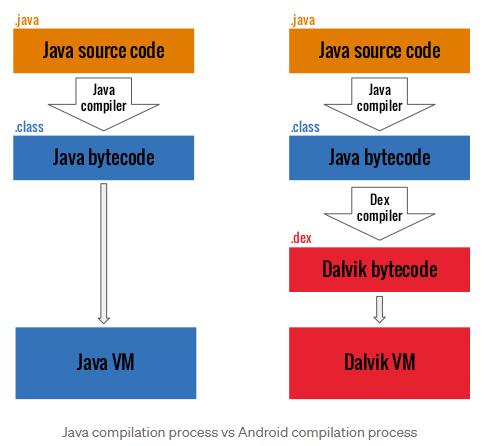


Dalvik bytecode is a crucial component of Android application (APK) files. It serves as the intermediate representation of an Android app's code, enabling its execution on Android devices. Here's a comprehensive explanation of Dalvik bytecode in the context of APK files:

**1. Compilation and DEX Files:**
   - Android applications are primarily developed in high-level programming languages such as Java or Kotlin. The code is initially compiled into standard Java bytecode using the `javac` compiler.
   - To make the code suitable for Android devices, it is then transformed into Dalvik bytecode using the `dx` tool. This results in .dex (Dalvik Executable) files containing the Dalvik bytecode.

**2. Register-Based Architecture:**
   - Dalvik bytecode employs a register-based architecture. In contrast to Java bytecode, which uses a stack-based architecture, Dalvik bytecode relies on a set of virtual registers for its operations.
   - Register-based architectures are often more efficient on resource-constrained devices, which is a significant advantage for mobile devices.

**3. Execution Environment:**
   - Dalvik bytecode is executed within the Dalvik Virtual Machine (DVM), which was the primary runtime environment for Android applications until Android 5.0 (Lollipop). Starting with Android 5.0, the Android Runtime (ART) took its place as the default runtime.

**4. APK Contents:**
   - APK files serve as containers for Android applications. They include not only Dalvik bytecode but also various other resources and metadata.
   - Key components of an APK file include:
     - Dalvik bytecode (.dex files): These contain the core application code.
     - AndroidManifest.xml: This XML file describes the app's structure, components, permissions, and other essential details.
     - Resources: These include images, layout files, and other assets used by the app.
     - Assets: Additional files, like sound or video, can be stored in the "assets" directory.

**5. Just-In-Time Compilation (JIT):**
   - Dalvik bytecode is often interpreted by the DVM, which reads and executes instructions sequentially. However, to enhance performance, Dalvik bytecode may also undergo Just-In-Time (JIT) compilation.
   - JIT compilation translates frequently executed bytecode segments into native machine code. This improves execution speed and efficiency.

**6. Multithreading and Concurrency:**
   - Android applications frequently involve multithreaded programming to provide responsive user interfaces. Dalvik bytecode supports multithreading, allowing apps to run multiple threads of execution concurrently.

**7. Object-Oriented Capabilities:**
   - Dalvik bytecode supports object-oriented programming (OOP) principles, including classes, objects, inheritance, encapsulation, and polymorphism.
   - It adheres to the Java language and includes Java libraries, which provide extensive functionality to Android apps.

**8. Security and Isolation:**
   - One of the core tenets of Android's security model is the isolation of applications from each other. Dalvik bytecode, executed in separate DVM instances, enforces this isolation.
   - Bytecode verification ensures that apps cannot tamper with the underlying Android system or other apps, contributing to the overall security of the Android platform.

**9. Transition to ART:**
   - While DVM was the primary runtime for Android applications, newer Android versions, beginning with Android 5.0, introduced the Android Runtime (ART) as the default runtime.
   - ART uses a different approach, performing Ahead-of-Time (AOT) compilation to native machine code for improved performance. However, it continues to support Dalvik bytecode to run older applications.

In summary, Dalvik bytecode is the heart of Android application execution. It is generated from high-level programming languages, stored in .dex files within APKs, executed in the DVM or ART runtime, and plays a vital role in ensuring the security and efficiency of Android applications, past and present. Understanding Dalvik bytecode is essential for Android developers, reverse engineers, and security analysts working with Android applications.

---------------------------------------------------------------------

## Step 3 — Extracting the manifest feature sets (S1–S4)

# Extract features for APKs

The easiest way to analyze APK files, is by using androguard analyze. It will start a iPython shell and has all modules loaded to get into action.

The three objects you get are a an APK object, **d** an array of DalvikVMFormat object and **dx** an Analysis object.

Inside the APK object, you can find all information about the APK, like package name, permissions, the AndroidManifest.xml or its resources.

The DalvikVMFormat corresponds to the **DEX** file found inside the APK file. You can get classes, methods or strings from the DEX file.

In [ ]:
path = '/content/689992492bf0914fc74f03314052e925df2425988f5cddcf54f0a1e0ca8692cf'
a, d, dx = AnalyzeAPK(path)  # a: app; d: dex; dx: analysis of dex

In [ ]:
# Access the AndroidManifest.xml file
manifest_xml = a.get_android_manifest_xml()

# Extract package name
package_name = manifest_xml.get("package")
package_name

    'S1': ['HardwareComponentsList'],
    'S2': ['RequestedPermissionList'],
    'S3': ['ActivityList', 'ServiceList', 'ContentProviderList', 'BroadcastReceiverList'],
    'S4': ['IntentFilterList'],
    'S5': ['RestrictedApiList'],
    'S6': ['UsedPermissionsList'],
    'S7': ['SuspiciousApiList'],
    'S8': ['URLDomainList']

# Feature sets from the manifest


**S1 Hardware components**

This first feature set contains
requested hardware components. If an application requests access to the camera, touchscreen or the GPS
module of the smartphone, these features need to be
declared in the manifest file. Requesting access to specific hardware has clearly security implications, as the
use of certain combinations of hardware often reflects
harmful behavior. An application which has access to
GPS and network modules is, for instance, able to collect location data and send it to an attacker over the
network.

In [ ]:
# Access the AndroidManifest.xml file
manifest_xml = a.get_android_manifest_xml()

#from xml.dom import minidom
xml_dom = minidom.parseString(etree.tostring(manifest_xml, pretty_print=True))

# Find hardware components
HardwareComponents = xml_dom.getElementsByTagName("uses-feature")

HardwareComponentsList = []
for HardwareComponent in HardwareComponents:
    if HardwareComponent.hasAttribute("android:name"):
        name = HardwareComponent.getAttribute("android:name")
        HardwareComponentsList.append(name)
        print(name)

**S2 Requested permissions:**

One of the most important security mechanisms introduced in Android is the permission system. Permissions are actively granted by the user at installation time and allow an application to
access security-relevant resources. malicious software tends to request
certain permissions more often than innocuous applications. For example, a great percentage of current
malware sends premium SMS messages and thus requests the SEND SMS permission. We thus gather all
permissions listed in the manifest in a feature set.


In [ ]:
# Find hardware components
Permissions = xml_dom.getElementsByTagName("uses-permission")

RequestedPermissionList = []
for Permission in Permissions:
    if Permission.hasAttribute("android:name"):
        name = Permission.getAttribute("android:name")
        RequestedPermissionList.append(name)
        print(name)

**S3 App components:**

There exist four different types of
components in an application, each defining different
interfaces to the system: activities, services, content
providers and broadcast receivers. Every application
can declare several components of each type in the
manifest. The names of these components are also
collected in a feature set, as the names may help to
identify well-known components of malware. For example, several variants of the so-called DroidKungFu
family share the name of particular services

In [ ]:
components = ['activity', 'service', 'receiver', 'provider']

for component in components:
  elements = xml_dom.getElementsByTagName(component)

  for element in elements:
      if element.hasAttribute("android:name"):
          name = element.getAttribute("android:name")
          print(component,' : ', name)

**S4 Filtered intents:**

Inter-process and intra-process communication on Android is mainly performed through intents: passive data structures exchanged as asynchronous messages and allowing information about events to be shared between different components and
applications. We collect all intents listed in the manifest as another feature set, as malware often listens to specific intents. A typical example of an intent message involved in malware is BOOT COMPLETED, which is used to trigger malicious activity directly after rebooting the smartphone.


In [ ]:
# Find hardware components
actions = xml_dom.getElementsByTagName("action")

for action in actions:
    if action.hasAttribute("android:name"):
        name = action.getAttribute("android:name")
        print(name)

In [ ]:
components = ['activity','service','receiver']

for component in components:
    print(component)
    print("---------")
    component_elements = xml_dom.getElementsByTagName(component)
    for element in component_elements:
        intent_filter_elements = element.getElementsByTagName('intent-filter')
        for intent_element in intent_filter_elements:
            # Handling the intent-filters that may have multiple actions
            action_elements = intent_element.getElementsByTagName('action')
            for action_element in action_elements:
                if action_element.hasAttribute("android:name"):
                    action = action_element.getAttribute("android:name")
                    print(action)
    print()

## Step 4 — Feature sets from the disassembled code (S5 and beyond)

# Feature sets from disassembled code


Android applications are developed in Java and compiled
into optimized bytecode for the Dalvik virtual machine.
This bytecode can be efficiently disassembled and provides
DREBIN with information about API calls and data used in
an application.

**S5 Restricted API calls:**

The Android permission system
restricts access to a series of critical API calls. Our
method searches for the occurrence of these calls in
the disassembled code in order to gain a deeper understanding of the functionality of an application. A particular case, revealing malicious behavior, is the use of
restricted API calls for which the required permissions
have not been requested. This may indicate that the
malware is using root exploits in order to surpass the
limitations imposed by the Android platform.


**S6 Used permissions:**

The complete set of calls extracted
in S5 is used as the ground for determining the subset of permissions that are both requested and actually
used. For this purpose, we implement the method introduced by Felt et al. [15] to match API calls and permissions. In contrast to S5, this feature set provides
a more general view on the behavior of an application
as multiple API calls can be protected by a single permission (e.g., sendMultipartTextMessage() and
sendTextMessage() both require that the SEND SMS
permission is granted to an application).

**S7 Suspicious API calls:**

Certain API calls allow access to
sensitive data or resources of the smartphone and are
frequently found in malware samples. As these calls
can specially lead to malicious behavior, they are extracted and gathered in a separated feature set. In particular, we collect the following types of API calls:
• API calls for accessing sensitive data, such as
getDeviceId() and getSubscriberId()
• API calls for communicating over the network, for example setWifiEnabled() and
execHttpRequest()
• API calls for sending and receiving SMS messages, such as sendTextMessage()
• API calls for execution of external commands
like Runtime.exec()
• API calls frequently used for obfuscation, such
as Cipher.getInstance()

**S8 Network addresses:**

Malware regularly establishes network connections to retrieve commands or exfiltrate
data collected from the device. Therefore, all IP addresses, hostnames and URLs found in the disassembled code are included in the last set of features. Some
of these addresses might be involved in botnets and
thus present in several malware samples, which can
help to improve the learning of detection patterns.

In [ ]:
!wget 'https://raw.githubusercontent.com/deqangss/adv-dnn-ens-malware/master/learner/drebin/BasicBlockAttrBuilder.py'
!wget 'https://raw.githubusercontent.com/deqangss/adv-dnn-ens-malware/master/learner/drebin/PermAPIMapping.py'
!wget 'https://raw.githubusercontent.com/deqangss/adv-dnn-ens-malware/master/learner/drebin/res/axplorerPermApi22Mapping.json'

!mkdir res
!mv axplorerPermApi22Mapping.json /content/res

# Smali code

Smali is a low-level programming language that is used as the intermediate representation for Android application code. It is designed to be human-readable and is used to represent the bytecode instructions that run on the Dalvik Virtual Machine (DVM), which is the predecessor to the Android Runtime (ART) used in Android applications.

Key characteristics of Smali include:

1. **Human-Readable**: Smali code is designed to be more human-readable than the actual Dalvik bytecode. It uses a text-based format that resembles assembly language, making it easier for developers and reverse engineers to read and understand the code.

2. **Instruction Set**: Smali represents Android application code as a series of instructions that are specific to the DVM. These instructions correspond to actions like method calls, variable assignments, and control flow statements.

3. **Intermediate Representation**: Smali is used as an intermediate representation during the compilation process of Android applications. Developers typically write their code in high-level languages like Java, which are then compiled into Smali code before being transformed into Dalvik bytecode.

4. **Reverse Engineering**: Smali is commonly used for reverse engineering Android applications. Security researchers and analysts often disassemble APK files to obtain the Smali code, allowing them to inspect an app's behavior and detect potential security vulnerabilities or malware.

Here's a simple example of Smali code that corresponds to a Java method that returns the sum of two integers:

Java Code:
```java
public int add(int a, int b) {
    return a + b;
}
```

Smali Code:
```smali
.method public add(II)I
    .locals 2
    .parameter "a"
    .parameter "b"

    .prologue
    .line 3
    add-int v0, p0, p1

    .line 4
    return v0
.end method
```

In this Smali code, you can see the method signature, the local variables, and the instructions for adding two integers and returning the result.

Smali code is an essential part of Android application analysis and is used in tools for tasks such as reverse engineering, security testing, and code analysis.

this function analyzes DEX bytecode files, extracts API sequences from Smali methods within those files, and organizes the API sequences by class. It also includes checks for sensitive and suspicious API calls

The code enters a loop to process Smali methods within the class.
Inside the method loop, the code processes the Smali code of each method:
It extracts information such as method headers, method names, parameter types, return value types, and invokes (API calls) within the method's instructions.
The code uses regular expressions to extract information from Smali instructions related to API calls (invocations). It checks for sensitive or suspicious APIs, and if an API call is found to be sensitive or suspicious, it extracts relevant information about the API call.
The extracted information, including the API call type, class name, method name, method signature, and more

In [ ]:
import BasicBlockAttrBuilder
from PermAPIMapping import AxplorerMapping
PMap =  AxplorerMapping()

UsedPermissions = []
RestrictedApiList = []
SuspiciousApiList = []
URLDomainList = []

for i, dd in enumerate(d):
    for method in dd.get_methods():
        g = dx.get_method(method)
        for BasicBlock in g.get_basic_blocks().get():
            Instructions = BasicBlockAttrBuilder.GetBasicBlockDalvikCode(BasicBlock)
            Apis, SuspiciousApis = BasicBlockAttrBuilder.GetInvokedAndroidApis(Instructions)
            Permissions, RestrictedApis = BasicBlockAttrBuilder.GetPermissionsAndApis(Apis, PMap, RequestedPermissionList, SuspiciousApiList)
            UsedPermissions.extend(Permissions)
            RestrictedApiList.extend(RestrictedApis)
            SuspiciousApiList.extend(SuspiciousApis)
            for Instruction in Instructions:
                URLSearch = re.search(r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+', Instruction, re.IGNORECASE)

                if URLSearch:
                    URL = URLSearch.group()
                    Domain = re.sub(r"(.*://)?([^/?]+).*", "\g<1>\g<2>", URL)
                    URLDomainList.append(Domain)

In [ ]:
print(UsedPermissions[:3])
print(RestrictedApiList[:3])
print(SuspiciousApiList[:3])
print(URLDomainList[:3])

In [ ]:
print(len(UsedPermissions))
print(len(RestrictedApiList))
print(len(SuspiciousApiList))
print(len(URLDomainList))

In [ ]:
UsedPermissions

## Step 5 — Feature extraction as done in the selected paper

# feature extraction in our selected paper




**Extracting Features**:
   - Various types of features are extracted from the analyzed APK file. These features include:
     - **Permissions**: A list of Android permissions requested by the app.
     - **Components**: A list of components (e.g., activities, services, receivers) defined in the app.
     - **Providers**: A list of content providers defined in the app.
     - **Intent Actions**: A list of intent actions used by the app.
     - **Hardware Information**: Information about the hardware features required by the app.
     - **API Sequences**: Sequences of API calls found in the app's Smali files.



the `max_number_of_smali_files` parameter is used to limit the number of Smali files (representing the methods within classes in Android app bytecode) that are processed. The purpose of this parameter is to control the number of Smali files processed to prevent excessive computational resources or to focus the analysis on a subset of the app's codebase.

Here's how it works in the code:

1. **Function Signature**:
   - `get_apis(dexes, max_number_of_smali_files)`: This function takes two parameters:
     - `dexes`: A list of DalvikVMFormat objects representing the DEX files (Dalvik Executable) in the Android app.
     - `max_number_of_smali_files`: An integer specifying the maximum number of Smali files to process.

2. **Processing Smali Files**:
   - The function iterates over the DEX files provided in the `dexes` parameter.
   - For each DEX file, it retrieves the Smali classes and methods from the DEX.
   - For each Smali method, it extracts information about the method's bytecode instructions, particularly focusing on method invocations (calls to other methods).

3. **Limiting the Number of Smali Files Processed**:
   - The variable `apis_classwise` is used to store the extracted API information class-wise.
   - After processing each Smali method within a class, the code checks if the number of processed Smali files (represented by `apis_classwise`) has exceeded the `max_number_of_smali_files` specified as a parameter.
   - If the limit is reached, the function returns the collected API information up to that point, effectively stopping further processing.

The `max_number_of_smali_files` parameter allows you to control the granularity of analysis. By setting this parameter, you can decide how many Smali files or methods you want to process during the feature extraction, enabling more focused or efficient analysis depending on your requirements.




```
def apk2features(apk_path, max_number_of_smali_files=10000, saving_path=None):
    """
    Extract the apk features, including dangerous permissions, suspicious intent actions, restricted apis, and dangerous apis
    Each permission: android permission
    Each intent action: intent action + '#.tag.#' + info of this intent
    Each api: 'invoke-type + ' ' + class_name + '->' + method_name + arguments + return_type+'#.tag.#'+ info of its
              class name and method definition path'

    :param apk_path: string, a path directs to an apk file, and otherwise an error is raised
    :param max_number_of_smali_files: integer, the maximum number of smali files
    :param timeout: integer, the elapsed time in minutes
    :param saving_path: string, a path directs to saving path
    """
    if not isinstance(apk_path, str):
        raise ValueError("Expected a path, but got {}".format(type(apk_path)))
    if not path.exists(apk_path):
        raise FileNotFoundError("Cannot find an apk file by following the path {}.".format(apk_path))
    if saving_path is None:
        warnings.warn("Save the features in current direction:{}".format(getcwd()))
        saving_path = path.join(getcwd(), 'api-graph')

    try:
        apk_path = path.abspath(apk_path)
        a, d, dx = AnalyzeAPK(apk_path)  # a: app; d: dex; dx: analysis of dex
    except Exception as e:
        raise ValueError("Fail to read and analyze the apk {}:{} ".format(apk_path, str(e)))

    # 1. get permissions
    try:
        permission_list = get_permissions(a)
    except Exception as e:
        raise ValueError("Fail to extract permissions {}:{} ".format(apk_path, str(e)))

    # 2. get components except for providers
    try:
        component_list = get_components(a)
    except Exception as e:
        raise ValueError("Fail to extract components {}:{} ".format(apk_path, str(e)))

    # 3.get providers
    try:
        provider_list = get_providers(a)
    except Exception as e:
        raise ValueError("Fail to extract providers {}:{} ".format(apk_path, str(e)))

    # 4. get intent actions
    try:
        intent_actions = get_intent_actions(a)
    except Exception as e:
        raise ValueError("Fail to extract intents {}:{} ".format(apk_path, str(e)))

    # 5. get hardware
    try:
        hardware_list = get_hardwares(a)
    except Exception as e:
        raise ValueError("Fail to extract hardware {}:{} ".format(apk_path, str(e)))

    # 6. get apis
    try:
        api_sequences = get_apis(d, max_number_of_smali_files)
    except Exception as e:
        raise ValueError("Fail to extract apis {}:{} ".format(apk_path, str(e)))

    features = []
    features.extend(permission_list + component_list + provider_list + intent_actions + hardware_list)
    features.extend(api_sequences)

    save_to_disk(features, saving_path)
    if len(features) <= 0:
        warnings.warn("No features found: " + apk_path)
    return saving_path


def permission_check(permission):
    if permission in DANGEROUS_PERMISSION_TAGS:
        return True
    else:
        return False


def get_permissions(app):
    """
    Get permissions
    :param app: androidguard.core.bytecodes.apk
    """
    rtn_permssions = []
    permissions = app.get_permissions()
    permissions += app.get_requested_third_party_permissions()
    for perm in permissions:
        rtn_permssions.append(perm + TAG_SPLITTER + PERMISSION)
    return rtn_permssions


def get_components(app):
    """
    Get activities
    :param app: androidguard.core.bytecodes.apk
    """
    component_names = []
    manifest_xml = app.get_android_manifest_xml()
    xml_dom = minidom.parseString(etree.tostring(manifest_xml, pretty_print=True))
    activity_elements = xml_dom.getElementsByTagName(ACTIVITY)
    for activity in activity_elements:
        if activity.hasAttribute("android:name"):
            activity_name = activity.getAttribute("android:name")
            component_names.append(activity_name + TAG_SPLITTER + ACTIVITY)
    service_elements = xml_dom.getElementsByTagName(SERVICE)
    for service in service_elements:
        if service.hasAttribute("android:name"):
            svc_name = service.getAttribute("android:name")
            component_names.append(svc_name + TAG_SPLITTER + SERVICE)
    receive_elements = xml_dom.getElementsByTagName(RECEIVER)
    for receiver in receive_elements:
        if receiver.hasAttribute("android:name"):
            receiver_name = receiver.getAttribute("android:name")
            component_names.append(receiver_name + TAG_SPLITTER + RECEIVER)

    return component_names


def get_providers(app):
    providers = []
    manifest_xml = app.get_android_manifest_xml()
    xml_dom = minidom.parseString(etree.tostring(manifest_xml, pretty_print=True))
    providers_elements = xml_dom.getElementsByTagName("provider")
    for provider in providers_elements:
        if provider.hasAttribute("android:name"):
            prov_name = provider.getAttribute("android:name")
            writer = io.StringIO()
            provider.writexml(writer)
            prov_extra_info = writer.getvalue()
            providers.append(prov_name + TAG_SPLITTER + PROVIDER + TAG_SPLITTER + prov_extra_info)
    return providers


def intent_action_check(action_in_question):
    for pre_action_name in INTENT_TAGS:
        if pre_action_name in action_in_question:
            return True
    else:
        return False


def get_intent_actions(app):
    """
    get intent actions from manifest, and the strings of intent actions in dex code will be neglected
    intent action starts with either of
    "android.intent.action",
    "com.android.vending",
    "android.net", and
    "com.android"
    :param app: androidguard.core.bytecodes.apk
    """
    actions = []

    manifest_xml = app.get_android_manifest_xml()
    xml_dom = minidom.parseString(etree.tostring(manifest_xml, pretty_print=True))

    def _analyze_component(component_elements, component_name):
        for element in component_elements:
            intent_filter_elements = element.getElementsByTagName('intent-filter')
            for intent_element in intent_filter_elements:
                # Handling the intent-filters that may have multiple actions
                action_elements = intent_element.getElementsByTagName('action')
                for i, action_element in enumerate(action_elements):
                    if action_element.hasAttribute("android:name"):
                        action = action_element.getAttribute("android:name")
                        # action_parent = copy.copy(intent_element)
                        # if len(action_elements) > 1:
                        #     action_elements_copy = action_parent.getElementsByTagName('action')
                        #     for _i in range(len(action_elements_copy)):
                        #         if _i != i:
                        #             action_parent.removeChild(action_elements_copy[_i])
                        # writer = io.StringIO()
                        # action_parent.writexml(writer)
                        # action_extra_info = writer.getvalue()
                        actions.append(action + TAG_SPLITTER + INTENT + TAG_SPLITTER + component_name)

    # 1. activities
    activity_elements = xml_dom.getElementsByTagName('activity')
    _analyze_component(activity_elements, 'activity')
    # 2. services
    service_elements = xml_dom.getElementsByTagName('service')
    _analyze_component(service_elements, 'service')
    # 3. broadcast receiver
    receiver_elements = xml_dom.getElementsByTagName('receiver')
    _analyze_component(receiver_elements, 'receiver')
    return actions


def get_hardwares(app):
    hardwares_rtn = []
    for hardware in app.get_features():
        hardwares_rtn.append(hardware + TAG_SPLITTER + HARDWARE)
    return hardwares_rtn


def check_suspicious_api(api_query):
    for specific_api in DANGEROUS_API_SIMLI_TAGS:
        if specific_api in api_query:
            return True
    else:
        return False


def check_sensitive_api(api_query):
    if api_query in sensitive_apis:
        return True
    else:
        return False


def get_apis(dexes, max_number_of_smali_files):
    """
    get api sequences by class-wise
    """
    if isinstance(dexes, DalvikVMFormat):
        dexes = [dexes]

    apis_classwise = []
    for dex in dexes:
        smali_classes = dex.get_classes()
        for smali_cls in smali_classes:
            if len(apis_classwise) > max_number_of_smali_files:
                return apis_classwise
            smali_methods = smali_cls.get_methods()
            apis = []
            for smali_mth in smali_methods:
                # class name + TAG_SPLITTER + .method + Modifier + method name + parameter type + return value type
                method_header = smali_mth.class_name + TAG_SPLITTER
                method_header += '.method ' + smali_mth.access_flags_string + ' ' + smali_mth.name + smali_mth.proto
                for instruction in smali_mth.get_instructions():
                    smali_code = instruction.get_name() + ' { ' + instruction.get_output()  # on win32 platform, 'instruction.get_output()' triggers the memory exception 'exit code -1073741571 (0xC00000FD)' sometimes
                    invoke_match = re.search(
                        r'^([ ]*?)(?P<invokeType>invoke\-([^ ]*?)) {(?P<invokeParam>([vp0-9,. ]*?)),? (?P<invokeObject>L(.*?);|\[L(.*?);)->(?P<invokeMethod>(.*?))\((?P<invokeParamType>(.*?))\)(?P<invokeReturnType>(.*?))$',
                        smali_code)
                    if invoke_match is None:
                        continue
                    invoke_type = invoke_match.group('invokeType')
                    class_name, method_name = invoke_match.group('invokeObject'), invoke_match.group('invokeMethod')
                    proto = '(' + invoke_match.group('invokeParamType') + ')' + invoke_match.group('invokeReturnType')
                    # todo: justify the method is not the type of overload
                    # note: androidguard provides the EncodedMethod type, which is indeed not helpful, sometimes it is problematic
                    # e.g., from now on (version 3.3.5), the encodedmethod is actually implemented in the parent class yet neglected by androidguard
                    if check_sensitive_api(class_name + '->' + method_name) or \
                            check_suspicious_api(class_name + '->' + method_name):
                        api_info = invoke_type + ' ' + class_name + '->' + method_name + proto + \
                                   TAG_SPLITTER + SYS_API + \
                                   TAG_SPLITTER + method_header
                        apis.append(api_info)
            if len(apis) <= 0:
                continue
            apis_classwise.append(apis)
    return apis_classwise


def save_to_disk(data, saving_path):
    dump_pickle(data, saving_path)


def read_from_disk(loading_path):
    return read_pickle(loading_path)

```

